

Pipeline: **Bronze** (raw + `ingestion_timestamp`, Parquet) → **EDA** → **Silver** (cleaned) → **Gold** (model-ready: sparse matrix, lookup, aggregates) → **Item-based collaborative filtering** → **Demo**.

## Step 0 – Setup & get the raw files

In [1]:
import os, re, io, html, zipfile, urllib.request, datetime as dt
from string import capwords

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# If the notebook is run from inside the notebook/ folder, work from the project root so that
# bronze/, silver/ and gold/ are created NEXT TO notebook/ (not inside it).
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working directory:", os.getcwd())

# ---- Data lake folders ----
for layer in ["bronze", "silver", "gold"]:
    os.makedirs(layer, exist_ok=True)

# ---- Raw files: use local copies if present, otherwise download the official zip ----
RAW = ["BX-Users.csv", "BX-Books.csv", "BX-Book-Ratings.csv"]
if not all(os.path.exists(f) for f in RAW):
    URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
    print("Downloading", URL)
    urllib.request.urlretrieve(URL, "book-crossings.zip")
    with zipfile.ZipFile("book-crossings.zip") as z:
        for name in z.namelist():
            base = os.path.basename(name)
            if base in RAW:
                with z.open(name) as src, open(base, "wb") as dst:
                    dst.write(src.read())
print({f: f"{os.path.getsize(f)/1e6:.1f} MB" for f in RAW})

Working directory: /home/claude/rs
{'BX-Users.csv': '12.3 MB', 'BX-Books.csv': '77.8 MB', 'BX-Book-Ratings.csv': '30.7 MB'}


## Step 1 – Bronze layer (untouched copy + `ingestion_timestamp`)
The files are **semicolon-separated** and **ISO-8859-1 (latin-1)** encoded; book titles also contain backslash-escaped quotes (`\"`).
Everything is read as **text** (no type conversion, no cleaning) so that Bronze stays an exact copy of the source. The only transformation is that the literal token `NULL` used by the source is read as a missing value.

In [2]:
READ_KW = dict(sep=";", encoding="latin-1", dtype=str, na_values=["NULL"], keep_default_na=False,
               quotechar='"', escapechar="\\")

ingestion_ts = pd.Timestamp.now(tz="UTC").tz_localize(None)

users_raw   = pd.read_csv("BX-Users.csv",        **READ_KW)
books_raw   = pd.read_csv("BX-Books.csv",        **READ_KW)
ratings_raw = pd.read_csv("BX-Book-Ratings.csv", **READ_KW)

for df in (users_raw, books_raw, ratings_raw):
    df["ingestion_timestamp"] = ingestion_ts

users_raw.to_parquet("bronze/users.parquet",     index=False)
books_raw.to_parquet("bronze/books.parquet",     index=False)
ratings_raw.to_parquet("bronze/ratings.parquet", index=False)

for f in sorted(os.listdir("bronze")):
    print(f"bronze/{f:20s} {os.path.getsize('bronze/'+f)/1e6:6.1f} MB")

bronze/books.parquet          21.7 MB
bronze/ratings.parquet         9.8 MB
bronze/users.parquet           4.5 MB


## Step 2 – Exploratory Data Analysis (reading the Bronze tables back)

In [3]:
users   = pd.read_parquet("bronze/users.parquet")
books   = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

for name, df in [("users", users), ("books", books), ("ratings", ratings)]:
    print(f"===== {name}: shape = {df.shape}")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                        "missing_%": (df.isna().mean()*100).round(2)}))
    print()

===== users: shape = (278858, 4)
                              dtype  missing  missing_%
User-ID                         str        0       0.00
Location                        str        0       0.00
Age                             str   110762      39.72
ingestion_timestamp  datetime64[us]        0       0.00

===== books: shape = (271379, 9)
                              dtype  missing  missing_%
ISBN                            str        0        0.0
Book-Title                      str        0        0.0
Book-Author                     str        0        0.0
Year-Of-Publication             str        0        0.0
Publisher                       str        0        0.0
Image-URL-S                     str        0        0.0
Image-URL-M                     str        0        0.0
Image-URL-L                     str        0        0.0
ingestion_timestamp  datetime64[us]        0        0.0

===== ratings: shape = (1149780, 4)
                              dtype  missing  missing_%


**EDA 1 – Shape, types, missing values.** Users: 278,858 rows; Books: 271,379 rows; Ratings: 1,149,780 rows. Every column is stored as text in Bronze. The only missing values are in `Age` (110,762 ≈ 39.7 % of users). → *Silver:* cast IDs/ages/years/ratings to proper numeric types, set impossible ages to null and fill with the median age, and drop unused columns.

rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610

Ratings equal to 0 : 716,109  (62.3 %)
Explicit (1-10)    : 433,671  (37.7 %)


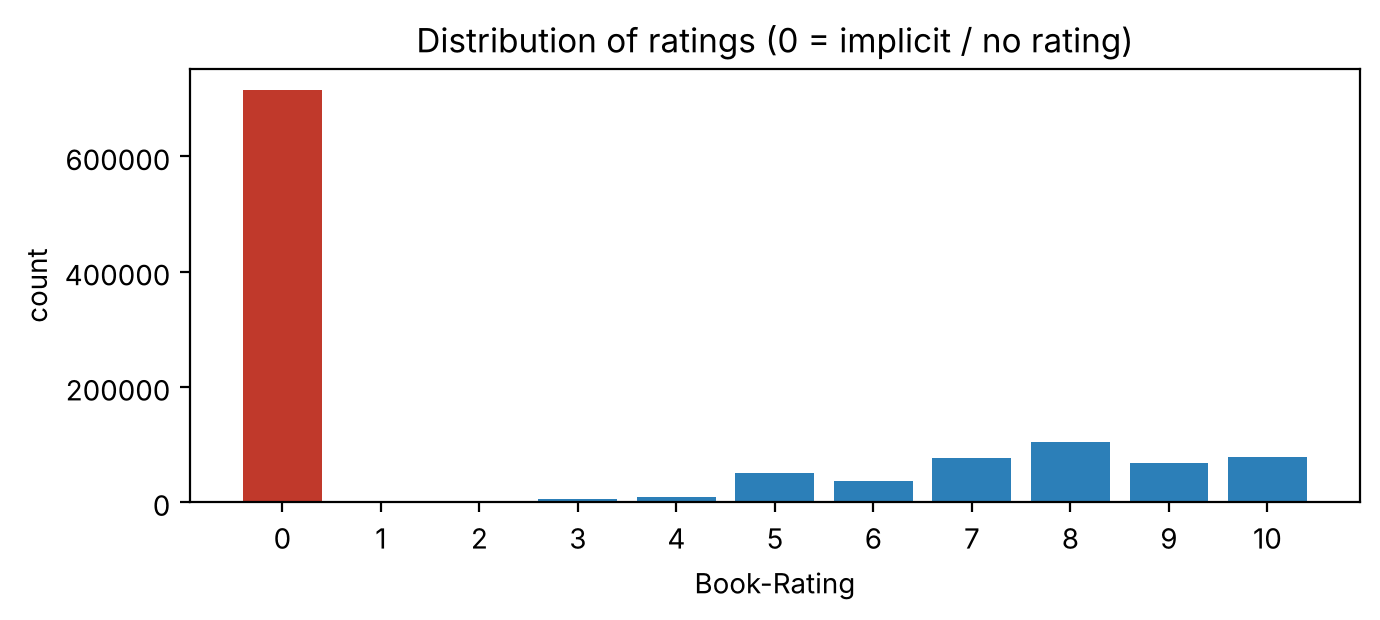

In [4]:
ratings["rating"] = ratings["Book-Rating"].astype(int)
vc = ratings["rating"].value_counts().sort_index()
print(vc.to_string())
print(f"\nRatings equal to 0 : {(ratings.rating==0).sum():,}  ({(ratings.rating==0).mean()*100:.1f} %)")
print(f"Explicit (1-10)    : {(ratings.rating>0).sum():,}  ({(ratings.rating>0).mean()*100:.1f} %)")

fig, ax = plt.subplots(figsize=(7,3.2))
ax.bar(vc.index, vc.values, color=["#c0392b"]+["#2c7fb8"]*10)
ax.set_xlabel("Book-Rating"); ax.set_ylabel("count"); ax.set_title("Distribution of ratings (0 = implicit / no rating)")
ax.set_xticks(range(0,11)); plt.tight_layout(); plt.show()

**EDA 2 – Ratings.** 716,109 of 1,149,780 ratings (**62.3 %**) are `0`, which means "no explicit rating"; only 433,671 are real 1–10 scores, and those are skewed high (mostly 7–10). → *Silver:* remove all 0 ratings and keep ratings 1–10.

count    168096.0
mean         34.8
std          14.4
min           0.0
25%          24.0
50%          32.0
75%          44.0
max         244.0

Age missing      : 110,762
Age < 5          : 882
Age > 100        : 366
Age 5..100 valid : 166,848


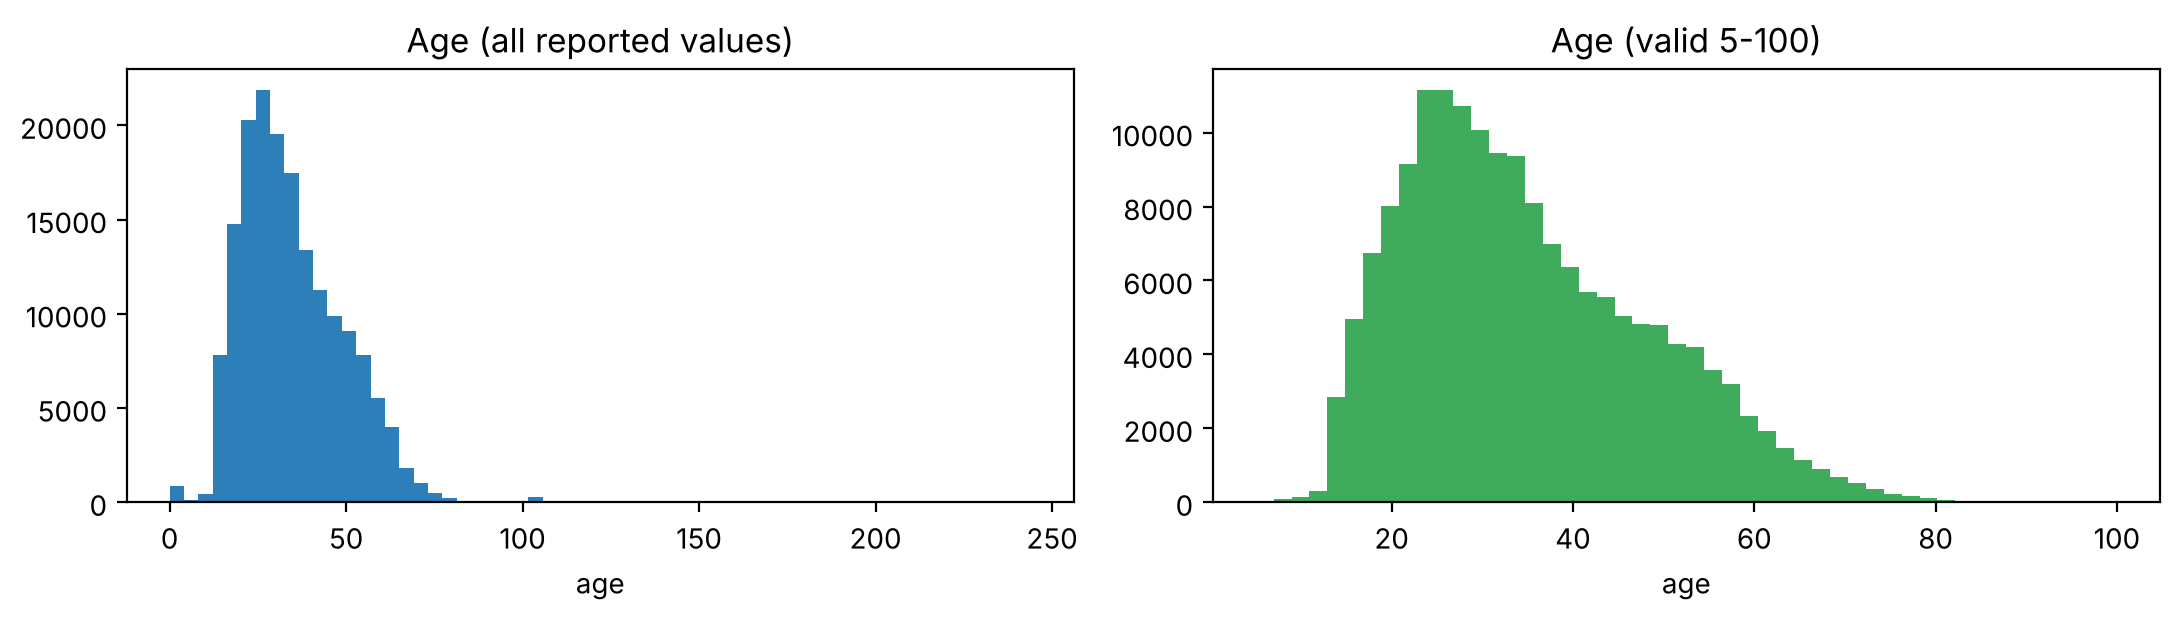

In [5]:
age = pd.to_numeric(users["Age"], errors="coerce")
print(age.describe().round(1).to_string())
print(f"\nAge missing      : {age.isna().sum():,}")
print(f"Age < 5          : {(age<5).sum():,}")
print(f"Age > 100        : {(age>100).sum():,}")
print(f"Age 5..100 valid : {age.between(5,100).sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(11,3.2))
ax[0].hist(age.dropna(), bins=60, color="#2c7fb8"); ax[0].set_title("Age (all reported values)"); ax[0].set_xlabel("age")
ax[1].hist(age[age.between(5,100)], bins=48, color="#41ab5d"); ax[1].set_title("Age (valid 5-100)"); ax[1].set_xlabel("age")
plt.tight_layout(); plt.show()

**EDA 3a – User ages.** 39.7 % of ages are missing; of the reported ages 882 are below 5 and 366 are above 100 (max 244) – impossible values. Valid ages are centred around 30–35. → *Silver:* set age < 5 or > 100 to null, then fill nulls with the **median** of the valid ages (robust to the skew and outliers).

count    271379.0
mean       1959.8
std         258.0
min           0.0
25%        1989.0
50%        1995.0
75%        2000.0
max        2050.0

Year == 0               : 4,619
Year > 2026 (future)   : 11   e.g. [2030, 2037, 2038, 2050]
0 < Year < 1800         : 2   e.g. [1376, 1378]
Plausible (1800-2026) : 266,747


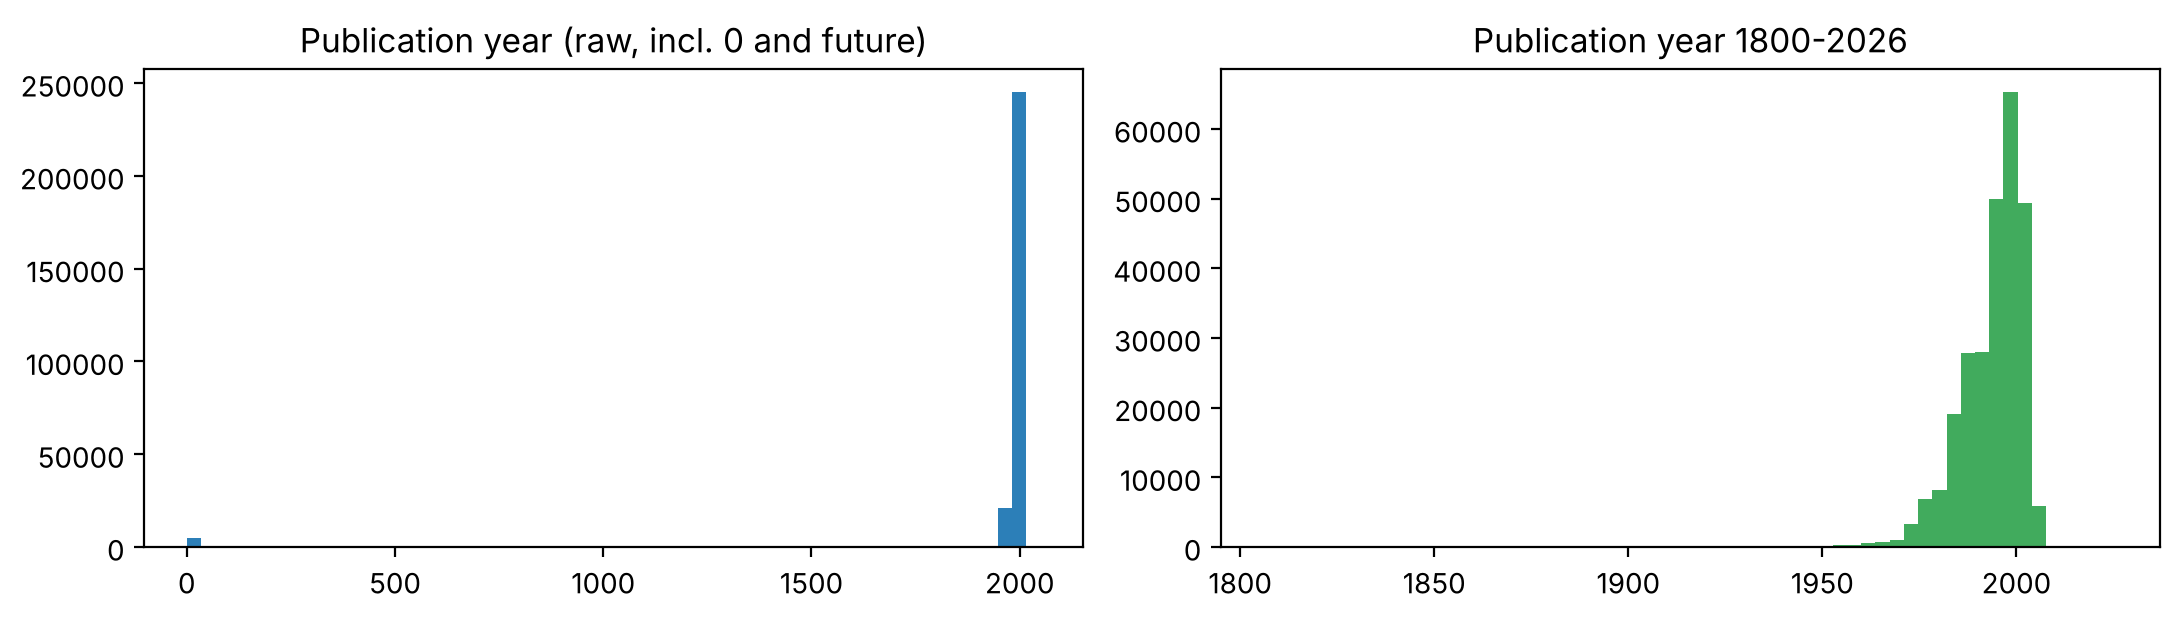

In [6]:
year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
this_year = dt.date.today().year
print(year.describe().round(1).to_string())
print(f"\nYear == 0               : {(year==0).sum():,}")
print(f"Year > {this_year} (future)   : {(year>this_year).sum():,}   e.g. {sorted(year[year>this_year].unique().tolist())}")
print(f"0 < Year < 1800         : {((year>0)&(year<1800)).sum():,}   e.g. {sorted(year[(year>0)&(year<1800)].unique().tolist())}")
valid = year[(year>=1800)&(year<=this_year)]
print(f"Plausible (1800-{this_year}) : {len(valid):,}")

fig, ax = plt.subplots(1, 2, figsize=(11,3.2))
ax[0].hist(year.dropna(), bins=60, color="#2c7fb8"); ax[0].set_title("Publication year (raw, incl. 0 and future)")
ax[1].hist(valid, bins=60, color="#41ab5d"); ax[1].set_title(f"Publication year 1800-{this_year}")
plt.tight_layout(); plt.show()

**EDA 3b – Publication years.** 4,619 books have year `0`, 11 have future years (2030–2050) and 2 have years before 1800 – all impossible. → *Silver:* set year `0`, future years (and pre-1800 typos) to null (they are not used by the recommender, so no imputation is needed).

--- ratings per user (all raw ratings, incl. 0) ---
users with >=1 rating : 105,283
median=1  mean=10.9  max=13,602
share with <=5 ratings  : 81.3 %
count with >=10 ratings : 13,097

--- ratings per book (all raw ratings, incl. 0) ---
books with >=1 rating : 340,556
median=1  mean=3.4  max=2,502
share with <=5 ratings  : 89.8 %
count with >=10 ratings : 18,319



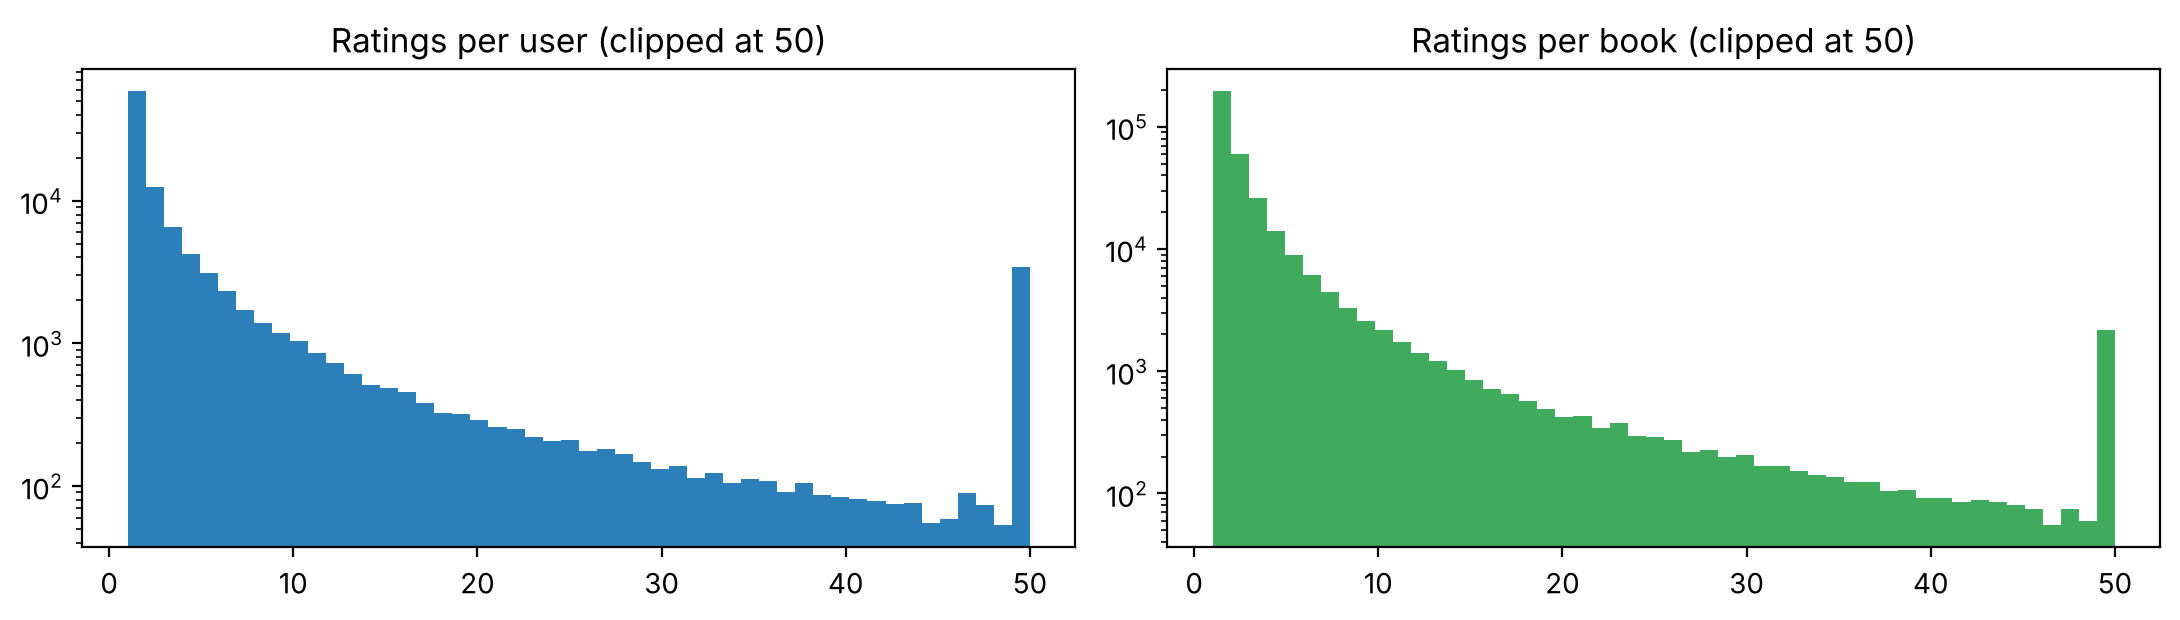

Candidate thresholds (iterated until stable):


,min_ratings (users & books),ratings,users,books,density_%
0,5,115219,6851,9085,0.185
1,10,41456,1820,2030,1.122
2,15,0,0,0,0.000
3,20,0,0,0,0.000


In [7]:
rate_u = ratings.groupby("User-ID").size()
rate_b = ratings.groupby("ISBN").size()

def describe_counts(s, label):
    print(f"--- ratings per {label} (all raw ratings, incl. 0) ---")
    print(f"{label}s with >=1 rating : {len(s):,}")
    print(f"median={s.median():.0f}  mean={s.mean():.1f}  max={s.max():,}")
    print(f"share with <=5 ratings  : {(s<=5).mean()*100:.1f} %")
    print(f"count with >=10 ratings : {(s>=10).sum():,}\n")
describe_counts(rate_u, "user"); describe_counts(rate_b, "book")

fig, ax = plt.subplots(1, 2, figsize=(11,3.2))
ax[0].hist(rate_u.clip(upper=50), bins=50, color="#2c7fb8"); ax[0].set_yscale("log"); ax[0].set_title("Ratings per user (clipped at 50)")
ax[1].hist(rate_b.clip(upper=50), bins=50, color="#41ab5d"); ax[1].set_yscale("log"); ax[1].set_title("Ratings per book (clipped at 50)")
plt.tight_layout(); plt.show()

# Effect of candidate thresholds on explicit ratings (1-10) after referential-integrity filtering
e = ratings[ratings.rating>0]
e = e[e["User-ID"].isin(users["User-ID"]) & e["ISBN"].isin(books["ISBN"])]
rows = []
for k in [5, 10, 15, 20]:
    x = e
    while True:
        n = len(x)
        x = x[x["User-ID"].map(x["User-ID"].value_counts()) >= k]
        x = x[x["ISBN"].map(x["ISBN"].value_counts()) >= k]
        if len(x) == n: break
    rows.append({"min_ratings (users & books)": k, "ratings": len(x), "users": x["User-ID"].nunique(),
                 "books": x["ISBN"].nunique(),
                 "density_%": round(len(x)/max(x["User-ID"].nunique()*x["ISBN"].nunique(), 1)*100, 3)})
print("Candidate thresholds (iterated until stable):"); pd.DataFrame(rows)

**EDA 4 – Ratings per user / per book.** Activity is extremely long-tailed: the median user and the median book each have **1** rating, 81.3 % of users and 89.8 % of books have ≤ 5 ratings, while only 13,097 users and 18,319 books have ≥ 10 ratings. → *Silver:* keep only users **and** books with at least **10 explicit ratings** (applied iteratively until stable). Reasoning: collaborative filtering and cosine similarity cannot be estimated reliably from one or two ratings; 10 is the standard minimum, and the threshold table above shows that 5 leaves a noisier matrix with many barely-supported books, while 15 or 20 collapse the data completely (iterating the filter on both users and books leaves nothing), so 10 is a good balance between reliability and coverage.

In [8]:
n_users, n_books, n_ratings = users.shape[0], books.shape[0], ratings.shape[0]
n_expl = int((ratings.rating>0).sum())
print(f"Possible user-book pairs   : {n_users:,} x {n_books:,} = {n_users*n_books:,}")
print(f"Observed ratings (all)     : {n_ratings:,}  -> density {n_ratings/(n_users*n_books)*100:.5f} %  | sparsity {100-n_ratings/(n_users*n_books)*100:.4f} %")
print(f"Observed explicit (1-10)   : {n_expl:,}  -> density {n_expl/(n_users*n_books)*100:.5f} %  | sparsity {100-n_expl/(n_users*n_books)*100:.4f} %")

Possible user-book pairs   : 278,858 x 271,379 = 75,676,205,182
Observed ratings (all)     : 1,149,780  -> density 0.00152 %  | sparsity 99.9985 %
Observed explicit (1-10)   : 433,671  -> density 0.00057 %  | sparsity 99.9994 %


**EDA 5 – Sparsity.** Of ≈ 75.7 billion possible user–book pairs only 1.15 M have any rating (and only 0.43 M an explicit one): the matrix is **> 99.99 % empty**. → *Gold:* store the rating matrix as a **sparse** (CSR) matrix; filtering to active users/books in Silver raises the density from ~0.0006 % to about 1 %.

## Step 3 – Silver layer (cleaning)
Rules applied: remove duplicates → keep ratings 1–10 → fix ages (null + median) → split `Location` → fix publication years → clean text (trim, standardise case, un-escape HTML, drop image URLs) → keep only ratings with existing user & book → keep users/books with **≥ 10 ratings**.

In [9]:
MIN_RATINGS = 10                      # threshold chosen from the EDA above
funnel = []                           # keeps a record of how many rows survive each rule
def log(step, r, u, b): funnel.append({"step": step, "ratings": r, "users": u, "books": b})

u = pd.read_parquet("bronze/users.parquet").drop(columns="ingestion_timestamp")
b = pd.read_parquet("bronze/books.parquet").drop(columns="ingestion_timestamp")
r = pd.read_parquet("bronze/ratings.parquet").drop(columns="ingestion_timestamp")
log("Bronze (raw)", len(r), len(u), len(b))

# ---- tidy names & types --------------------------------------------------------------------
u = u.rename(columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
b = b.rename(columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
                      "Year-Of-Publication": "year", "Publisher": "publisher"})
r = r.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})
b = b.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])            # image URLs not needed

u["user_id"] = u["user_id"].astype(int); r["user_id"] = r["user_id"].astype(int)
r["rating"]  = r["rating"].astype(int)
u["age"]     = pd.to_numeric(u["age"], errors="coerce")
b["year"]    = pd.to_numeric(b["year"], errors="coerce")
for df in (b, r):
    df["isbn"] = df["isbn"].str.strip().str.upper()

# ---- 1. duplicates --------------------------------------------------------------------------
u = u.drop_duplicates().drop_duplicates("user_id")
b = b.drop_duplicates().drop_duplicates("isbn")
r = r.drop_duplicates().drop_duplicates(["user_id", "isbn"], keep="last")
log("1. remove duplicates", len(r), len(u), len(b))

# ---- 2. ratings: keep 1..10 -----------------------------------------------------------------
r = r[r["rating"].between(1, 10)]
log("2. keep ratings 1-10 (drop 0)", len(r), len(u), len(b))

# ---- 3. user age: <5 or >100 -> null, then median fill ---------------------------------------
u.loc[(u["age"] < 5) | (u["age"] > 100), "age"] = np.nan
median_age = u["age"].median()
n_age_null = int(u["age"].isna().sum())
u["age"] = u["age"].fillna(median_age).astype("int16")
print(f"Ages set to null / missing before fill: {n_age_null:,}  -> filled with median = {median_age:.0f}")

# ---- 4. location -> city, state, country ----------------------------------------------------
def smart_case(s):
    """Title-case only when the text is entirely upper- or lower-case (keeps 'McDonald', 'JRR' style mixes)."""
    if not isinstance(s, str): return s
    return capwords(s) if (s.isupper() or s.islower()) else s

def clean_text(s):
    s = s.astype("string").map(lambda x: html.unescape(x) if isinstance(x, str) else x)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s.replace({"": pd.NA, "n/a": pd.NA, "N/A": pd.NA})

parts = u["location"].astype("string").str.split(",", expand=True)
def part(i):  return clean_text(parts[i]) if i in parts.columns else pd.Series(pd.NA, index=u.index, dtype="string")
u["city"]    = part(0)
n_parts      = parts.apply(lambda row: sum(isinstance(x, str) and x.strip() != "" for x in row), axis=1)
last_part    = parts.apply(lambda row: next((x for x in reversed(row.tolist()) if isinstance(x, str) and x.strip()), pd.NA), axis=1)
u["country"] = clean_text(last_part).where(n_parts >= 2)          # a 1-part location is only a city
u["state"]   = clean_text(parts[1]).where(n_parts >= 3)           # state only exists for "city, state, country"
for c in ["city", "state", "country"]:
    u[c] = u[c].map(smart_case)
u["country"] = u["country"].replace({"Usa": "USA", "Uk": "UK", "Uae": "UAE"})
u = u.drop(columns="location")

# ---- 5. publication year: 0 / future / impossible -> null ------------------------------------
this_year = dt.date.today().year
bad_year = (b["year"] == 0) | (b["year"] > this_year) | (b["year"] < 1800)
print(f"Publication years set to null: {int(bad_year.sum()):,}")
b.loc[bad_year, "year"] = np.nan
b["year"] = b["year"].astype("Int16")

# ---- 6. clean text columns ------------------------------------------------------------------
for c in ["title", "author", "publisher"]:
    b[c] = clean_text(b[c]).map(smart_case)
b = b.dropna(subset=["title"])
log("3-6. fix ages / location / years / text", len(r), len(u), len(b))

# ---- 7. referential integrity ---------------------------------------------------------------
r = r[r["user_id"].isin(u["user_id"]) & r["isbn"].isin(b["isbn"])]
log("7. keep ratings with existing user & book", len(r), len(u), len(b))

# ---- 8. minimum-ratings filter (users AND books), iterated until stable -----------------------
while True:
    n = len(r)
    r = r[r["user_id"].map(r["user_id"].value_counts()) >= MIN_RATINGS]
    r = r[r["isbn"].map(r["isbn"].value_counts())       >= MIN_RATINGS]
    if len(r) == n: break
u = u[u["user_id"].isin(r["user_id"])]
b = b[b["isbn"].isin(r["isbn"])]
log(f"8. users & books with >= {MIN_RATINGS} ratings", len(r), len(u), len(b))

users_silver, books_silver, ratings_silver = (u.reset_index(drop=True), b.reset_index(drop=True),
                                              r.reset_index(drop=True).astype({"rating": "int8"}))
ratings_silver = ratings_silver[["user_id", "isbn", "rating"]]
pd.DataFrame(funnel)

Ages set to null / missing before fill: 112,010  -> filled with median = 32


Publication years set to null: 4,625


,step,ratings,users,books
0,Bronze (raw),1149780,278858,271379
1,1. remove duplicates,1149780,278858,271064
2,2. keep ratings 1-10 (drop 0),433671,278858,271064
3,3-6. fix ages / location / years / text,433671,278858,271064
4,7. keep ratings with existing user & book,383853,278858,271064
5,8. users & books with >= 10 ratings,41469,1820,2030


In [10]:
users_silver.to_parquet("silver/users.parquet",     index=False)
books_silver.to_parquet("silver/books.parquet",     index=False)
ratings_silver.to_parquet("silver/ratings.parquet", index=False)

print("Silver shapes -> users", users_silver.shape, "| books", books_silver.shape, "| ratings", ratings_silver.shape)
print("\nMissing values after cleaning:")
print(pd.concat({"users": users_silver.isna().sum(), "books": books_silver.isna().sum(),
                 "ratings": ratings_silver.isna().sum()}, axis=1).fillna("-").to_string())
users_silver.head()

Silver shapes -> users (1820, 5) | books (2030, 5) | ratings (41469, 3)

Missing values after cleaning:
          users books ratings
user_id     0.0     -     0.0
age         0.0     -       -
city        7.0     -       -
country    41.0     -       -
state      86.0     -       -
isbn          -   0.0     0.0
title         -   0.0       -
author        -   0.0       -
year          -   4.0       -
publisher     -   0.0       -
rating        -     -     0.0


,user_id,age,city,country,state
0,243,32,Arden Hills,USA,Minnesota
1,254,24,Minneapolis,USA,Minnesota
2,638,20,San Diego,USA,California
3,805,34,Sonoma,USA,California
4,882,23,Berkeley,USA,California


In [11]:
books_silver.head(8)

,isbn,title,author,year,publisher
0,0440234743,The Testament,John Grisham,1999,Dell
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison,1994,Plume
2,0971880107,Wild Animus,Rich Shapero,2004,Too Far
3,0345402871,Airframe,Michael Crichton,1997,Ballantine Books
4,0345417623,Timeline,Michael Crichton,2000,Ballantine Books
5,0446310786,To Kill a Mockingbird,Harper Lee,1988,Little Brown & Company
6,0449005615,Seabiscuit: An American Legend,Laura Hillenbrand,2002,Ballantine Books
7,0671888587,I'll Be Seeing You,Mary Higgins Clark,1994,Pocket


In [12]:
print("rating range :", ratings_silver.rating.min(), "-", ratings_silver.rating.max())
print("age range    :", users_silver.age.min(), "-", users_silver.age.max())
print("year range   :", books_silver.year.min(), "-", books_silver.year.max())
print("duplicates   : users", users_silver.duplicated().sum(), "| books", books_silver.duplicated().sum(),
      "| ratings", ratings_silver.duplicated(["user_id","isbn"]).sum())
print("orphans      :", (~ratings_silver.user_id.isin(users_silver.user_id)).sum(), "users,",
      (~ratings_silver.isbn.isin(books_silver.isbn)).sum(), "books")
print("min ratings per user / per book:", ratings_silver.user_id.value_counts().min(), "/", ratings_silver.isbn.value_counts().min())
print("\nTop countries:"); print(users_silver.country.value_counts().head(6).to_string())

rating range : 1 - 10
age range    : 9 - 90
year range   : 1930 - 2004
duplicates   : users 0 | books 0 | ratings 0
orphans      : 0 users, 0 books
min ratings per user / per book: 10 / 10

Top countries:
country
USA               1410
Canada             179
United Kingdom      30
Australia           21
Malaysia            19
Portugal            14


## Step 4 – Gold layer (model-ready data)

In [13]:
rs = pd.read_parquet("silver/ratings.parquet")
bs = pd.read_parquet("silver/books.parquet")
us = pd.read_parquet("silver/users.parquet")

# ---- index mappings (row = user, column = book) ----
user_ids = np.sort(rs["user_id"].unique());  book_ids = np.sort(rs["isbn"].unique())
user_index = pd.DataFrame({"user_id": user_ids, "row": np.arange(len(user_ids))})
book_index = pd.DataFrame({"isbn": book_ids,  "col": np.arange(len(book_ids))})

row = rs["user_id"].map(user_index.set_index("user_id")["row"]).to_numpy()
col = rs["isbn"].map(book_index.set_index("isbn")["col"]).to_numpy()

# ---- sparse user x book rating matrix (CSR) ----
R = sp.csr_matrix((rs["rating"].to_numpy(dtype=np.float32), (row, col)), shape=(len(user_ids), len(book_ids)))
sp.save_npz("gold/user_book_matrix.npz", R)
user_index.to_parquet("gold/user_index.parquet", index=False)
book_index.to_parquet("gold/book_index.parquet", index=False)

# ---- book lookup (id, title, author) ----
book_lookup = bs[["isbn", "title", "author", "year", "publisher"]].rename(columns={"isbn": "book_id"})
book_lookup = book_lookup[book_lookup.book_id.isin(book_ids)].sort_values("book_id")
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

# ---- aggregates ----
user_agg = (rs.groupby("user_id")["rating"].agg(avg_rating="mean", n_ratings="count").round(3).reset_index()
              .merge(us[["user_id", "age", "country"]], on="user_id", how="left"))
book_agg = (rs.groupby("isbn")["rating"].agg(avg_rating="mean", n_ratings="count").round(3).reset_index()
              .rename(columns={"isbn": "book_id"}).merge(book_lookup[["book_id", "title", "author"]], on="book_id"))
user_agg.to_parquet("gold/user_aggregates.parquet", index=False)
book_agg.to_parquet("gold/book_aggregates.parquet", index=False)

print(f"Rating matrix: {R.shape[0]:,} users x {R.shape[1]:,} books | stored ratings = {R.nnz:,} "
      f"| density = {R.nnz/(R.shape[0]*R.shape[1])*100:.3f} % | sparsity = {100-R.nnz/(R.shape[0]*R.shape[1])*100:.3f} %")
print(f"Dense float32 would need {R.shape[0]*R.shape[1]*4/1e6:.1f} MB; CSR needs {(R.data.nbytes+R.indices.nbytes+R.indptr.nbytes)/1e6:.2f} MB")
print("\nGold files:"); 
for f in sorted(os.listdir("gold")): print(f"  gold/{f:28s}{os.path.getsize('gold/'+f)/1e6:7.2f} MB")

Rating matrix: 1,820 users x 2,030 books | stored ratings = 41,469 | density = 1.122 % | sparsity = 98.878 %
Dense float32 would need 14.8 MB; CSR needs 0.34 MB

Gold files:
  gold/book_aggregates.parquet        0.08 MB
  gold/book_index.parquet             0.03 MB
  gold/book_lookup.parquet            0.07 MB
  gold/user_aggregates.parquet        0.03 MB
  gold/user_book_matrix.npz           0.10 MB
  gold/user_index.parquet             0.02 MB


In [14]:
print("Book lookup"); display(book_lookup.head(5))
print("User aggregates"); display(user_agg.sort_values("n_ratings", ascending=False).head(5))
print("Book aggregates (most rated)"); display(book_agg.sort_values("n_ratings", ascending=False).head(8))

Book lookup


,book_id,title,author,year,publisher
1352,0020199600,Great Gatsby (reissue),F. Scott Fitzgerald,1988,Scribner Paper Fiction
1247,0020442203,"Lion, the Witch and the Wardrobe",C.S. Lewis,1970,MacMillan Publishing Company.
649,002542730X,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley & Sons Inc
1464,0028604199,Once upon a More Enlightened Time: More Politi...,James Finn Garner,1995,MacMillan Publishing Company.
511,0060002050,On a Wicked Dawn (Cynster Novels),Stephanie Laurens,2002,Avon Books


User aggregates


,user_id,avg_rating,n_ratings,age,country
59,11676,7.705,954,32,NaN
86,16795,7.818,242,47,USA
607,95359,8.005,195,33,USA
668,104636,8.733,187,32,USA
737,114368,6.784,176,33,USA


Book aggregates (most rated)


,book_id,avg_rating,n_ratings,title,author
281,0316666343,8.238,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.610,177,The Da Vinci Code,Dan Brown
205,0312195516,8.492,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.664,125,The Secret Life of Bees,Sue Monk Kidd
1520,059035342X,9.042,119,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling
1100,0446672211,8.296,115,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts
44,0060928336,8.124,113,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells
869,043935806X,9.072,111,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling


## Step 5 – Item-based collaborative filtering
1. Load the rating matrix **from the Gold layer** and transpose it so that rows = books, columns = users.
2. Fit `NearestNeighbors(metric="cosine")` on the sparse book×user matrix (brute-force cosine – the right choice for sparse data).
3. `similar_books(title)` returns the 10 most similar books.
4. `recommend(user_id, n)` scores each candidate book by Σ similarity × the user's rating over the books they rated highly, removes already-read books and returns the top *n*.

In [15]:
# ---- 1. load Gold ----
R_gold     = sp.load_npz("gold/user_book_matrix.npz").tocsr()          # users x books
user_index = pd.read_parquet("gold/user_index.parquet")
book_index = pd.read_parquet("gold/book_index.parquet")
lookup     = pd.read_parquet("gold/book_lookup.parquet").set_index("book_id")
book_agg   = pd.read_parquet("gold/book_aggregates.parquet").set_index("book_id")

item_user = R_gold.T.tocsr()                                           # books x users
isbn_of_col  = book_index.sort_values("col")["isbn"].to_numpy()
col_of_isbn  = dict(zip(book_index["isbn"], book_index["col"]))
row_of_user  = dict(zip(user_index["user_id"], user_index["row"]))
titles       = lookup.loc[isbn_of_col, "title"].to_numpy()
authors      = lookup.loc[isbn_of_col, "author"].to_numpy()
def _norm(t):  return re.sub(r"[^a-z0-9]+", " ", str(t).lower()).strip()
def _base(t):  # title without "(edition/series)" suffixes and ": subtitle"  -> groups different editions of one book
    t = re.sub(r"\(.*?\)", " ", str(t)); t = re.split(r"\s:\s|:", t)[0]
    return _norm(t)
norm_title   = np.array([_norm(t) for t in titles])                  # full title (used for look-ups)
base_title   = np.array([_base(t) for t in titles])                  # edition-independent title (used to drop duplicates)
n_rat        = np.asarray((item_user > 0).sum(axis=1)).ravel()
print("book x user matrix:", item_user.shape, "| stored ratings:", item_user.nnz)

# ---- 2. cosine nearest neighbours between books ----
K = 60                                                                  # neighbours kept per book (candidates)
nn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=K + 1).fit(item_user)
dist, idx = nn.kneighbors(item_user)
sim = 1.0 - dist                                                        # cosine similarity
print("neighbour table:", idx.shape)

book x user matrix: (2030, 1820) | stored ratings: 41469
neighbour table: (2030, 61)


In [16]:
# ---- 3. similar books by title ----
def find_book(title):
    """Resolve a (partial, case-insensitive) title to a matrix column; prefer the most-rated edition."""
    q = _norm(title)
    hits = np.where(norm_title == q)[0]
    if len(hits) == 0: hits = np.where(base_title == _base(title))[0]
    if len(hits) == 0:
        hits = np.where(np.char.find(norm_title.astype(str), q) >= 0)[0]
    if len(hits) == 0:
        raise ValueError(f"No book matching '{title}' in the Gold layer.")
    return int(hits[np.argmax(n_rat[hits])])

def similar_books(title, n=10):
    c = find_book(title)
    out, shown = [], set()
    for j, s in zip(idx[c], sim[c]):
        if j == c or base_title[j] == base_title[c] or base_title[j] in shown:   # skip itself / other editions / repeats
            continue
        shown.add(base_title[j])
        out.append({"title": titles[j], "author": authors[j], "similarity": round(float(s), 3), "n_ratings": int(n_rat[j])})
        if len(out) == n: break
    print(f"Books most similar to: {titles[c]}  ({authors[c]})")
    return pd.DataFrame(out, index=range(1, len(out)+1))

similar_books("Harry Potter and the Sorcerer's Stone")

Books most similar to: Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))  (J. K. Rowling)


,title,author,similarity,n_ratings
1,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,0.411,72
2,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,0.316,59
3,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,0.254,78
4,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,0.243,111
5,Fried Green Tomatoes at the Whistle Stop Cafe,Fannie Flagg,0.189,18
6,Love Story,Erich Segal,0.170,10
7,Anne of Green Gables (Anne of Green Gables Nov...,L.m. Montgomery,0.163,31
8,Anne of Ingleside (Anne of Green Gables Novels...,L.m. Montgomery,0.156,13
9,Like Water for Chocolate: A Novel in Monthly I...,Laura Esquivel,0.155,25
10,"Blood of the Fold (Sword of Truth, Book 3)",Terry Goodkind,0.154,12


In [17]:
similar_books("The Lovely Bones: A Novel")

Books most similar to: The Lovely Bones: A Novel  (Alice Sebold)


,title,author,similarity,n_ratings
1,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.219,115
2,Lucky : A Memoir,Alice Sebold,0.218,57
3,The Da Vinci Code,Dan Brown,0.178,177
4,The Pilot's Wife : A Novel,Anita Shreve,0.176,101
5,Good in Bed,Jennifer Weiner,0.176,99
6,Nights in Rodanthe,Nicholas Sparks,0.170,33
7,The Pact: A Love Story,Jodi Picoult,0.168,23
8,The Lake House,James Patterson,0.166,27
9,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154,53
10,The Book of Ruth (Oprah's Book Club (Paperback)),Jane Hamilton,0.153,48


In [18]:
# ---- 4. recommend(user_id, n) ----
def user_profile(user_id):
    r_ = row_of_user[user_id]
    s, e = R_gold.indptr[r_], R_gold.indptr[r_ + 1]
    return R_gold.indices[s:e], R_gold.data[s:e]            # (book columns, ratings)

def liked_books(user_id, min_rating=8):
    cols, vals = user_profile(user_id)
    m = vals >= min_rating
    d = pd.DataFrame({"title": titles[cols[m]], "author": authors[cols[m]], "rating": vals[m].astype(int)})
    return d.sort_values("rating", ascending=False, kind="stable").reset_index(drop=True)

def recommend(user_id, n=10, min_rating=8):
    """Item-based CF: score(j) = sum over liked books i of  sim(i, j) * rating(user, i)."""
    if user_id not in row_of_user:                           # cold start -> popular, well-rated books
        pop = book_agg[book_agg.n_ratings >= 20].sort_values(["avg_rating", "n_ratings"], ascending=False).head(n)
        return pop[["title", "author"]].assign(score=np.nan).reset_index(drop=True)

    cols, vals = user_profile(user_id)
    seen_cols  = set(cols.tolist())
    seen_titles = {base_title[c] for c in cols}
    liked = cols[vals >= min_rating]; liked_r = vals[vals >= min_rating]
    if len(liked) == 0:                                      # fall back to the user's best-rated books
        top = np.argsort(-vals)[:5]; liked, liked_r = cols[top], vals[top]

    score, why = {}, {}
    for c, rt in zip(liked, liked_r):
        for j, s in zip(idx[c], sim[c]):
            if j == c or j in seen_cols or base_title[j] in seen_titles:      # drop already-read books/editions
                continue
            w = s * rt
            score[j] = score.get(j, 0.0) + w
            if j not in why or w > why[j][0]: why[j] = (w, titles[c])
    top = sorted(score.items(), key=lambda kv: -kv[1])
    out, used = [], set()
    for j, sc in top:
        if base_title[j] in used: continue                   # one row per distinct book (editions merged)
        used.add(base_title[j])
        out.append({"title": titles[j], "author": authors[j], "score": round(sc, 2), "because_you_liked": why[j][1]})
        if len(out) == n: break
    return pd.DataFrame(out, index=range(1, len(out)+1))
print("recommend() ready")

recommend() ready


## Step 6 – Demo & sanity check

In [19]:
# pick three users with different activity levels (deterministic: 90th / 55th / 20th percentile among users with >= 6 liked books)
ua = pd.read_parquet("gold/user_aggregates.parquet")
ua["n_liked"] = np.asarray((R_gold >= 8).sum(axis=1)).ravel()[ua["user_id"].map(row_of_user).to_numpy()]
cand = ua[ua.n_liked >= 6].sort_values(["n_ratings", "user_id"]).reset_index(drop=True)   # users with a usable taste profile
demo_users = [int(cand.loc[int(len(cand)*q), "user_id"]) for q in (0.90, 0.55, 0.20)]
print("Demo users:", demo_users)
print(ua.set_index("user_id").loc[demo_users, ["n_ratings", "n_liked", "avg_rating", "age", "country"]])

Demo users: [43842, 140662, 97694]
         n_ratings  n_liked  avg_rating  age country
user_id                                             
43842           43       33       8.256   32     NaN
140662          19       13       7.684   30     USA
97694           12       11       8.750   25  Canada


In [20]:
for uid in demo_users[:1]:
    print("="*110); print(f"USER {uid}  –  books rated highly (>= 8)"); print("="*110)
    display(liked_books(uid).head(12))
    print(f"TOP 10 RECOMMENDATIONS for user {uid}")
    display(recommend(uid, n=10))

USER 43842  –  books rated highly (>= 8)


,title,author,rating
0,A Light in the Attic,Shel Silverstein,10
1,Chocolat,Joanne Harris,10
2,Big Fish,Daniel Wallace,10
3,Hard Eight : A Stephanie Plum Novel (A Stephan...,Janet Evanovich,10
4,To the Nines: A Stephanie Plum Novel,Janet Evanovich,10
5,Silence of the Lambs,Thomas Harris,10
6,Seven Up (A Stephanie Plum Novel),Janet Evanovich,10
7,Lucky : A Memoir,Alice Sebold,10
8,A Prayer for Owen Meany,John Irving,10
9,Angry Housewives Eating Bon Bons,Lorna Landvik,10


TOP 10 RECOMMENDATIONS for user 43842


,title,author,score,because_you_liked
1,Three Fates,Nora Roberts,10.02,Hard Eight : A Stephanie Plum Novel (A Stephan...
2,Four To Score (A Stephanie Plum Novel),Janet Evanovich,9.65,Seven Up (A Stephanie Plum Novel)
3,Two for the Dough,Janet Evanovich,9.64,Seven Up (A Stephanie Plum Novel)
4,Dog Handling,Clare Naylor,9.61,Fishbowl (Red Dress Ink (Paperback))
5,High Five (A Stephanie Plum Novel),Janet Evanovich,9.58,Hard Eight : A Stephanie Plum Novel (A Stephan...
6,Three To Get Deadly : A Stephanie Plum Novel (...,Janet Evanovich,9.22,Seven Up (A Stephanie Plum Novel)
7,The Dirty Girls Social Club: A Novel,Alisa Valdes-Rodriguez,9.07,Angry Housewives Eating Bon Bons
8,Writ of Execution,Perri O'Shaughnessy,9.00,Seven Up (A Stephanie Plum Novel)
9,Hot Six : A Stephanie Plum Novel (A Stephanie ...,Janet Evanovich,8.96,Seven Up (A Stephanie Plum Novel)
10,Someone to Watch Over Me : A Novel,Judith McNaught,8.14,Angry Housewives Eating Bon Bons


In [21]:
for uid in demo_users[1:2]:
    print("="*110); print(f"USER {uid}  –  books rated highly (>= 8)"); print("="*110)
    display(liked_books(uid).head(12))
    print(f"TOP 10 RECOMMENDATIONS for user {uid}")
    display(recommend(uid, n=10))

USER 140662  –  books rated highly (>= 8)


,title,author,rating
0,I Know This Much Is True,Wally Lamb,10
1,Midwives: A Novel,Chris Bohjalian,10
2,To Kill a Mockingbird,Harper Lee,10
3,Along Came a Spider (Alex Cross Novels),James Patterson,10
4,The Guardian,Nicholas Sparks,10
5,The Notebook,Nicholas Sparks,10
6,Message in a Bottle,Nicholas Sparks,10
7,A Walk to Remember,Nicholas Sparks,10
8,The Rescue,Nicholas Sparks,10
9,A Bend in the Road,Nicholas Sparks,10


TOP 10 RECOMMENDATIONS for user 140662

,title,author,score,because_you_liked
1,The Wedding,Nicholas Sparks,14.17,The Guardian
2,Nights in Rodanthe,Nicholas Sparks,10.77,The Guardian
3,The Gift,Danielle Steel,8.38,A Walk to Remember
4,Mixed Blessings,Danielle Steel,7.72,The Rescue
5,Divine Evil,Nora Roberts,7.51,Cloud Nine
6,Night Whispers,Judith McNaught,5.94,The Rescue
7,That Camden Summer,Lavyrle Spencer,5.71,A Walk to Remember
8,Sam's Letters to Jennifer,James Patterson,5.64,The Guardian
9,The Secret Life of Bees,Sue Monk Kidd,5.31,A Walk to Remember
10,"Then Again, Maybe I Won't",Judy Blume,5.24,A Bend in the Road


In [22]:
for uid in demo_users[2:3]:
    print("="*110); print(f"USER {uid}  –  books rated highly (>= 8)"); print("="*110)
    display(liked_books(uid).head(12))
    print(f"TOP 10 RECOMMENDATIONS for user {uid}")
    display(recommend(uid, n=10))


USER 97694  –  books rated highly (>= 8)


,title,author,rating
0,Me Talk Pretty One Day,David Sedaris,10
1,Under the Banner of Heaven : A Story of Violen...,Jon Krakauer,10
2,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,10
3,Slightly Single (Red Dress Ink (Paperback)),Wendy Markham,9
4,Southern Cross,Patricia Daniels Cornwell,9
5,The King of Torts,John Grisham,9
6,Bad Heir Day,Wendy Holden,9
7,The Ladies Auxiliary (Ballantine Reader's Circle),Tova Mirvis,8
8,The Devil Wears Prada : A Novel,Lauren Weisberger,8
9,On the Street Where You Live,Mary Higgins Clark,8


TOP 10 RECOMMENDATIONS for user 97694


,title,author,score,because_you_liked
1,Jemima J: A Novel About Ugly Ducklings and Swans,Jane Green,6.35,Mr. Maybe
2,Asking for Trouble: A Novel,Elizabeth Young,5.72,Mr. Maybe
3,Out of the Blue (Red Dress Ink (Paperback)),Isabel Wolff,5.44,Slightly Single (Red Dress Ink (Paperback))
4,Name & Address Withheld (Red Dress Ink (Paperb...,Jane Sigaloff,5.28,Slightly Single (Red Dress Ink (Paperback))
5,Running with Scissors,Augusten Burroughs,5.14,Under the Banner of Heaven : A Story of Violen...
6,Milkrun,Sarah Mlynowski,5.13,Mr. Maybe
7,The Secret Life of Bees,Sue Monk Kidd,4.92,The Ladies Auxiliary (Ballantine Reader's Circle)
8,Loose Screws (Red Dress Ink (Paperback)),Karen Templeton,4.76,Slightly Single (Red Dress Ink (Paperback))
9,A Patchwork Planet (Ballantine Reader's Circle),Anne Tyler,4.75,The Ladies Auxiliary (Ballantine Reader's Circle)
10,Shopaholic Takes Manhattan (Summer Display Opp...,Sophie Kinsella,4.58,The Devil Wears Prada : A Novel


In [23]:
# ---- automatic sanity checks over 300 random users ----
rng = np.random.default_rng(42)
sample = rng.choice(user_index["user_id"].to_numpy(), size=300, replace=False)
ok_len = ok_unseen = 0; authors_shared = 0; checked = 0
for uid in sample:
    rec = recommend(int(uid), n=10)
    cols, _ = user_profile(int(uid)); seen_t = {titles[c] for c in cols}; seen_b = {base_title[c] for c in cols}; seen_a = {authors[c] for c in cols}
    ok_len    += len(rec) == 10
    ok_unseen += not any((t in seen_t) or (_base(t) in seen_b) for t in rec["title"])
    authors_shared += any(a in seen_a for a in rec["author"]); checked += 1
print(f"Users checked                                  : {checked}")
print(f"Returned a full list of 10 recommendations     : {ok_len/checked*100:.1f} %")
print(f"No already-read book (any edition) in list              : {ok_unseen/checked*100:.1f} %")
print(f"List contains an author the user already read  : {authors_shared/checked*100:.1f} %  (plausibility signal)")

Users checked                                  : 300
Returned a full list of 10 recommendations     : 100.0 %
No already-read book (any edition) in list              : 100.0 %
List contains an author the user already read  : 89.3 %  (plausibility signal)


## Summary
| Layer | Content | Key operations |
|-------|---------|----------------|
| **Bronze** | `bronze/users|books|ratings.parquet` | read with `sep=";"`, latin-1, everything as text; `ingestion_timestamp` added; nothing cleaned |
| **Silver** | `silver/users|books|ratings.parquet` | duplicates removed; ratings 0 dropped; age < 5 / > 100 → null → median; `Location` → city/state/country; year 0/future → null; text trimmed, case standardised, HTML un-escaped; image URLs dropped; referential integrity; users & books with ≥ 10 ratings |
| **Gold** | `gold/user_book_matrix.npz` (CSR), `book_lookup`, `user_aggregates`, `book_aggregates`, index maps | sparse matrix + readable titles + average rating / rating counts |
| **Model** | item-based CF, cosine `NearestNeighbors` | `similar_books(title)` and `recommend(user_id, n)` |

**Limitations / ideas:** raw-rating cosine favours popular books; mean-centred (adjusted) cosine, a hybrid with content features (author/publisher) or matrix factorisation (ALS/SVD) could improve results; a proper evaluation would hold out ratings and measure precision@k / recall@k.